# Laboratorio 4: Segmentación de imágenes - Caso DermAlpes

**Caso:** DermAlpes, herramienta de apoyo para delimitar automáticamente lesiones de piel en imágenes dermatoscópicas.

**Integrantes:** Juan Camilo Panadero - Jose Luis Parra

**Objetivo:** Construir y evaluar un método de segmentación no supervisada para delimitar lesiones de piel mediante K-medias, representando cada píxel con sus características de color y posición. El laboratorio incluye la preparación de las imágenes y máscaras, la exploración de los pesos de color y posición, la selección de `K` mediante el coeficiente de silueta y el análisis crítico de las limitaciones del método.

---

## Actividad 1: pipeline de preparación y representación

Aunque las carpetas contienen el conjunto completo de 900 imágenes de ISIC 2016, este laboratorio utiliza únicamente las 20 imágenes indicadas en el enunciado: 15 para ajuste y 5 para prueba. Las máscaras de referencia se reservan para evaluar las máscaras estimadas; no se utilizan para construir la representación de los píxeles.

### Justificación del protocolo

La separación entre ajuste y prueba evita evaluar el método sobre imágenes que participaron en la toma de decisiones. Las 15 imágenes de ajuste se utilizarán para explorar los pesos de color y posición y seleccionar `K`; las 5 imágenes de prueba permanecerán aisladas hasta la evaluación final. Esta separación permite obtener una estimación más honesta de la capacidad de generalización del método.

In [1]:

from pathlib import Path

# NumPy representa las imágenes y las características como arreglos numéricos.
import numpy as np
import matplotlib.pyplot as plt
# Pillow se utiliza para leer las imágenes y las máscaras.
from PIL import Image
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer

# Se intenta trabajar desde la carpeta del notebook; el segundo caso permite
# ejecutar esta celda desde la raíz del repositorio.
RUTA_LAB = Path.cwd()
if not (RUTA_LAB / "ISBI2016_ISIC_Part1_Training_Data").is_dir():
    RUTA_LAB = RUTA_LAB / "202620" / "Laboratorios" / "L4"
RUTA_IMAGENES = RUTA_LAB / "ISBI2016_ISIC_Part1_Training_Data"
RUTA_MASCARAS = RUTA_LAB / "ISBI2016_ISIC_Part1_Training_GroundTruth"

# Se reduce la resolución para que K-medias sea ejecutable.
# Pillow expresa el tamaño como (ancho, alto).
TAMANO_IMAGEN = (256, 256)

# Estas 15 imágenes se usan para explorar y seleccionar la configuración.
IDS_AJUSTE = [
    "ISIC_0000085", "ISIC_0000086", "ISIC_0000089", "ISIC_0000094",
    "ISIC_0000108", "ISIC_0000114", "ISIC_0000116", "ISIC_0000122",
    "ISIC_0000133", "ISIC_0000137", "ISIC_0000150", "ISIC_0000153",
    "ISIC_0000156", "ISIC_0000157", "ISIC_0000112",
]
# Estas 5 imágenes se reservan para la evaluación final.
IDS_PRUEBA = [
    "ISIC_0000087", "ISIC_0000105", "ISIC_0000110", "ISIC_0000123",
    "ISIC_0000128",
]
# La lista completa permite verificar las 20 parejas imagen-máscara.
IDS_USADOS = IDS_AJUSTE + IDS_PRUEBA




## Carga y preparación de imágenes y máscaras

Los canales RGB y las coordenadas se normalizan a `[0, 1]`. Las máscaras se convierten de `0/255` a `0/1`. Si fuera necesario redimensionar una máscara, se utiliza vecino más cercano para conservar su naturaleza binaria.

### Decisiones de preparación

Las imágenes originales tienen una resolución alta para el número de agrupamientos que se deben explorar. Por esta razón se redimensionan a `256 × 256`, lo que produce `65.536` píxeles por imagen en lugar de varios millones. Esta decisión hace viable el experimento en memoria y tiempo, aunque puede eliminar detalles pequeños de las lesiones; por ello debe considerarse como una limitación del análisis.

La imagen RGB se redimensiona con `LANCZOS`, apropiado para valores continuos de color. La máscara se redimensiona con vecino más cercano, porque sus valores representan categorías y no deben convertirse en tonos intermedios. Después se binariza explícitamente para garantizar que solo contenga `0` y `1`.

In [2]:
# Construye la ruta de la imagen a partir de su identificador ISIC.
def ruta_imagen(image_id):
    return RUTA_IMAGENES / f"{image_id}.jpg"


# Las máscaras tienen el mismo identificador y el sufijo _Segmentation.
def ruta_mascara(image_id):
    return RUTA_MASCARAS / f"{image_id}_Segmentation.png"


def cargar_imagen(image_id, tamano=TAMANO_IMAGEN):
    """Carga una imagen RGB y la redimensiona al tamaño indicado."""
    # Se informa explícitamente si falta un archivo seleccionado.
    ruta = ruta_imagen(image_id)
    if not ruta.is_file():
        raise FileNotFoundError(f"No se encontró la imagen: {ruta}")
    # Convertir a RGB garantiza tres canales aunque el archivo tenga otro modo.
    with Image.open(ruta) as imagen:
        imagen = imagen.convert("RGB")
        if tamano is not None and imagen.size != tamano:
            imagen = imagen.resize(tamano, resample=Image.Resampling.LANCZOS)
        return np.asarray(imagen)


def cargar_mascara(image_id, tamano=None):
    """Carga, redimensiona opcionalmente y binariza la máscara de referencia."""
    ruta = ruta_mascara(image_id)
    if not ruta.is_file():
        raise FileNotFoundError(f"No se encontró la máscara: {ruta}")
    
    # L convierte la máscara a escala de grises, con un único canal.
    with Image.open(ruta) as mascara:
        mascara = mascara.convert("L")
        # El vecino más cercano conserva los valores discretos de la máscara.
        if tamano is not None and mascara.size != tamano:
            mascara = mascara.resize(tamano, resample=Image.Resampling.NEAREST)
        valores = np.asarray(mascara)

    # Convierte los valores originales 0/255 en etiquetas binarias 0/1.
    return (valores > 0).astype(np.uint8)


def validar_pares(image_ids):
    """Verifica que cada imagen seleccionada tenga su máscara correspondiente."""
    # La máscara solo se valida aquí; no participa en la representación de X.
    for image_id in image_ids:
        imagen = cargar_imagen(image_id, tamano=TAMANO_IMAGEN)
        mascara = cargar_mascara(image_id, tamano=TAMANO_IMAGEN)
        if imagen.shape[:2] != mascara.shape:
            raise ValueError(f"Dimensiones incompatibles para {image_id}")
        if not np.isin(mascara, [0, 1]).all():
            raise ValueError(f"La máscara de {image_id} no es binaria")


validar_pares(IDS_USADOS)
print(f"Pares imagen-máscara validados: {len(IDS_USADOS)}")
print(f"Imágenes de ajuste: {len(IDS_AJUSTE)} | Imágenes de prueba: {len(IDS_PRUEBA)}")


Pares imagen-máscara validados: 20
Imágenes de ajuste: 15 | Imágenes de prueba: 5


## Representación `[beta·R, beta·G, beta·B, lambda·x, lambda·y]`

Cada fila de la matriz representa un píxel. `x` aumenta de izquierda a derecha y `y` aumenta de arriba hacia abajo. La función conserva por separado la forma `(H, W)` de la imagen para poder reconstruir posteriormente las etiquetas de K-medias como una máscara.

La representación combina apariencia y ubicación mediante:

`[beta·R, beta·G, beta·B, lambda·x, lambda·y]`

El parámetro `beta` controla la influencia del color y `lambda` controla la influencia espacial. Como todas las variables base se encuentran en `[0, 1]`, la razón `lambda/beta` determina el peso relativo entre ambos tipos de información. Si `lambda=0`, K-medias agrupa únicamente por color; si `beta=0`, agrupa únicamente por posición. No se permite que ambos sean cero porque en ese caso todos los píxeles tendrían la misma representación.

La matriz resultante tiene una fila por píxel y cinco columnas. Por ejemplo, para una imagen de `256 × 256`, su forma es `(65536, 5)`. La máscara de referencia no participa en esta transformación: se mantiene separada para evitar fuga de información.

In [3]:
def representar_imagen(imagen, beta=1.0, lambda_=1.0):
    """Construye una matriz de características con una fila por píxel."""
    imagen = np.asarray(imagen)
    if imagen.ndim != 3 or imagen.shape[2] != 3:
        raise ValueError("La imagen debe tener forma (alto, ancho, 3)")
    if beta < 0 or lambda_ < 0 or (beta == 0 and lambda_ == 0):
        raise ValueError("beta y lambda deben ser no negativos y no ambos cero")

    alto, ancho, _ = imagen.shape
    # Los canales RGB pasan de [0, 255] a [0, 1].
    colores = imagen.astype(np.float32) / 255.0
    # x representa columnas y y representa filas, ambas normalizadas a [0, 1].
    x = np.linspace(0.0, 1.0, ancho, dtype=np.float32)
    y = np.linspace(0.0, 1.0, alto, dtype=np.float32)
    coordenada_x, coordenada_y = np.meshgrid(x, y)

    # Cada fila final corresponde a un píxel y contiene cinco características.
    caracteristicas = np.column_stack([
    # ravel aplana cada canal siguiendo el mismo orden de píxeles.
        beta * colores[:, :, 0].ravel(),
        beta * colores[:, :, 1].ravel(),
        beta * colores[:, :, 2].ravel(),
        lambda_ * coordenada_x.ravel(),
        lambda_ * coordenada_y.ravel(),
    ])
    return caracteristicas.astype(np.float32)


def crear_pipeline(beta=1.0, lambda_=1.0):
    """Crea el pipeline parametrizable solicitado en la actividad."""
    # FunctionTransformer adapta nuestra función al formato de Pipeline.
    return Pipeline([
    # K-means devuelve etiquetas en una dimensión; aquí recuperamos la imagen.
        (
            "representacion",
            FunctionTransformer(
                lambda imagen: representar_imagen(imagen, beta, lambda_),
                validate=False,
            ),
        ),
    ])


def reconstruir_mascara(etiquetas, forma):
    """Devuelve las etiquetas 1D de los píxeles con forma (alto, ancho)."""
    alto, ancho = forma
    etiquetas = np.asarray(etiquetas)
    if etiquetas.size != alto * ancho:
        raise ValueError("El número de etiquetas no coincide con la imagen")
    return etiquetas.reshape((alto, ancho))


## Verificación con una imagen de ajuste

Se prueba una configuración que combina color y posición. La matriz resultante queda lista para utilizarse como entrada de `KMeans` en la Actividad 2.

Esta sección funciona como una prueba de calidad del pipeline, no como una evaluación de segmentación. Se verifica que la imagen y la máscara puedan cargarse, que tengan dimensiones compatibles, que la matriz tenga cinco características por píxel y que la máscara conserve los valores binarios. La visualización permite confirmar que la imagen y la máscara pertenecen al mismo identificador y que no quedaron invertidas o desalineadas.

In [4]:
# Se verifica una imagen de ajuste sin consultar la máscara para construir X.
image_id = IDS_AJUSTE[0]
imagen = cargar_imagen(image_id, tamano=TAMANO_IMAGEN)
mascara_referencia = cargar_mascara(
    image_id,
    tamano=TAMANO_IMAGEN,
)

# Esta configuración combina color y posición.
beta = 1.0
lambda_ = 0.5
pipeline = crear_pipeline(beta=beta, lambda_=lambda_)
# X será la entrada de KMeans en la Actividad 2.
X = pipeline.transform(imagen)

assert X.shape == (imagen.shape[0] * imagen.shape[1], 5)
assert mascara_referencia.shape == imagen.shape[:2]
assert np.isin(mascara_referencia, [0, 1]).all()

print(f"Imagen: {image_id}")
print(f"Dimensiones: {imagen.shape[0]} x {imagen.shape[1]}")
print(f"Matriz de representación: {X.shape}")
print(f"Rango de colores normalizados: [{imagen.min() / 255:.3f}, {imagen.max() / 255:.3f}]")
print(f"Valores de la máscara: {np.unique(mascara_referencia)}")


Imagen: ISIC_0000085
Dimensiones: 256 x 256
Matriz de representación: (65536, 5)
Rango de colores normalizados: [0.000, 0.847]
Valores de la máscara: [0 1]


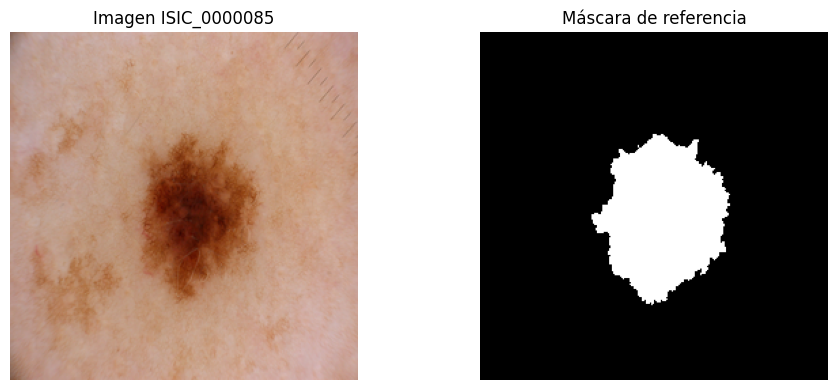

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(imagen)
axes[0].set_title(f"Imagen {image_id}")
axes[1].imshow(mascara_referencia, cmap="gray")
axes[1].set_title("Máscara de referencia")
for ax in axes:
    ax.axis("off")
plt.tight_layout()


## Actividad 2: agrupación y selección de K

Se exploran diez razones distintas entre posición y color. Para cada combinación se entrenan modelos K-medias con `K` entre 2 y 8. El coeficiente de silueta se calcula sobre una muestra reproducible de píxeles y se utiliza para seleccionar el mejor valor de `K`. Solo se usan las 15 imágenes de ajuste.

### Justificación de la exploración

Se incluyen los casos extremos de solo color y solo posición, además de configuraciones intermedias y configuraciones donde la posición tiene mayor peso. Esto permite observar cómo cambia la geometría del espacio de características cuando se modifica `lambda/beta`. Multiplicar simultáneamente `beta` y `lambda` por una misma constante no constituye una configuración nueva, porque conserva las distancias relativas; por eso se comparan razones diferentes.

En las configuraciones que utilizan color se fija `beta=1` como valor de referencia y se modifica `lambda` para controlar directamente la razón `lambda/beta`. Esta elección no significa que el color tenga un valor universal o que se haya ignorado la posibilidad de cambiar su escala; evita repetir configuraciones equivalentes. Por ejemplo, `(beta=1, lambda=0.5)` y `(beta=2, lambda=1)` tienen la misma razón y producen las mismas asignaciones de K-medias, salvo diferencias numéricas menores. La única excepción es el caso de solo posición, donde se establece `beta=0` para eliminar completamente las características de color.

K-medias es no supervisado: aprende los centroides y asigna grupos usando únicamente la matriz `X`. Las máscaras de referencia no se usan para ajustar el modelo ni para seleccionar `K`. En esta actividad los números de grupo no se interpretan todavía como fondo o lesión; esa decisión corresponde a la construcción de la máscara en una etapa posterior.

El coeficiente de silueta mide qué tan cerca está cada píxel de su propio grupo frente a los demás grupos. Valores cercanos a `1` indican grupos compactos y separados; valores cercanos a `0` indican solapamiento, y valores negativos sugieren asignaciones problemáticas. Como cada imagen tiene muchos píxeles, se utiliza una muestra de hasta 5.000 observaciones con semilla `42`, de modo que el cálculo sea ejecutable y reproducible.

In [6]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd

# Las parejas (beta, lambda) tienen razones lambda/beta distintas.
# Se incluyen explícitamente los casos de solo color y solo posición.
CONFIGURACIONES = [
    {"beta": 1.0, "lambda_": 0.0, "nombre": "solo_color"},
    {"beta": 1.0, "lambda_": 0.1, "nombre": "lambda_beta_0.1"},
    {"beta": 1.0, "lambda_": 0.25, "nombre": "lambda_beta_0.25"},
    {"beta": 1.0, "lambda_": 0.5, "nombre": "lambda_beta_0.5"},
    {"beta": 1.0, "lambda_": 0.75, "nombre": "lambda_beta_0.75"},
    {"beta": 1.0, "lambda_": 1.0, "nombre": "lambda_beta_1.0"},
    {"beta": 1.0, "lambda_": 2.0, "nombre": "lambda_beta_2.0"},
    {"beta": 1.0, "lambda_": 4.0, "nombre": "lambda_beta_4.0"},
    {"beta": 1.0, "lambda_": 8.0, "nombre": "lambda_beta_8.0"},
    {"beta": 0.0, "lambda_": 1.0, "nombre": "solo_posicion"},
]
VALORES_K = range(2, 9)
TAMANO_MUESTRA_SILUETA = 5000
SEMILLA_MUESTRA = 42
SEMILLA_KMEANS = 42

# Se guardan los modelos para reutilizar sus grupos en la Actividad 3.
MODELOS_ACTIVIDAD_2 = {}


def indices_muestra(n_elementos, tamano, semilla):
    """Selecciona índices sin reemplazo de forma reproducible."""
    rng = np.random.default_rng(semilla)
    cantidad = min(tamano, n_elementos)
    return rng.choice(n_elementos, size=cantidad, replace=False)


def evaluar_kmeans_imagen(image_id, configuracion):
    """Calcula la silueta para K=2,...,8 en una imagen de ajuste."""
    imagen = cargar_imagen(image_id, tamano=TAMANO_IMAGEN)
    X_imagen = crear_pipeline(
        beta=configuracion["beta"],
        lambda_=configuracion["lambda_"],
    ).transform(imagen)
    indices = indices_muestra(
        len(X_imagen), TAMANO_MUESTRA_SILUETA, SEMILLA_MUESTRA
    )
    X_muestra = X_imagen[indices]
    # Las imágenes tienen millones de píxeles; para explorar K se ajusta
    # K-means sobre la misma muestra reproducible usada por la silueta.
    X_entrenamiento = X_muestra
    resultados = []

    for k in VALORES_K:
        modelo = KMeans(
            n_clusters=k,
            random_state=SEMILLA_KMEANS,
            n_init=10,
        )
        # Se ajusta K-medias únicamente con características, sin máscaras.
        etiquetas = modelo.fit_predict(X_entrenamiento)
        MODELOS_ACTIVIDAD_2[(image_id, configuracion["nombre"], k)] = modelo
        silueta = silhouette_score(
            X_muestra,
            etiquetas,
            metric="euclidean",
        )
        resultados.append({
            "imagen": image_id,
            "configuracion": configuracion["nombre"],
            "beta": configuracion["beta"],
            "lambda_": configuracion["lambda_"],
            "K": k,
            "silueta": silueta,
            "muestra_silueta": len(indices),
            "semilla_muestra": SEMILLA_MUESTRA,
        })
    return resultados


In [7]:
# Se ejecuta el experimento sobre las 15 imágenes de ajuste.
resultados_actividad_2 = []
for image_id in IDS_AJUSTE:
    for configuracion in CONFIGURACIONES:
        resultados_actividad_2.extend(
            evaluar_kmeans_imagen(image_id, configuracion)
        )

tabla_silueta = pd.DataFrame(resultados_actividad_2)
mejor_k_por_imagen = (
    tabla_silueta.loc[
        tabla_silueta.groupby(["imagen", "configuracion"])["silueta"].idxmax()
    ]
    .sort_values(["configuracion", "imagen"])
    .reset_index(drop=True)
)

promedio_configuraciones = (
    mejor_k_por_imagen.groupby(
        ["configuracion", "beta", "lambda_"]
    )["silueta"]
    .mean()
    .sort_values(ascending=False)
    .rename("silueta_promedio")
    .reset_index()
)

print(f"Filas evaluadas: {len(tabla_silueta)}")
print(f"Muestra por silueta: hasta {TAMANO_MUESTRA_SILUETA} píxeles")
print(f"Semilla de muestra: {SEMILLA_MUESTRA}")
display(promedio_configuraciones)


Filas evaluadas: 1050
Muestra por silueta: hasta 5000 píxeles
Semilla de muestra: 42


,configuracion,beta,lambda_,silueta_promedio
0,solo_color,1.0,0.00,0.737508
1,lambda_beta_0.1,1.0,0.10,0.704221
2,lambda_beta_0.25,1.0,0.25,0.612231
3,lambda_beta_0.5,1.0,0.50,0.490475
4,lambda_beta_0.75,1.0,0.75,0.444762
5,lambda_beta_1.0,1.0,1.00,0.441057
6,lambda_beta_2.0,1.0,2.00,0.428080
7,solo_posicion,0.0,1.00,0.411685
8,lambda_beta_8.0,1.0,8.00,0.408397
9,lambda_beta_4.0,1.0,4.00,0.407798


### Interpretación preliminar de los resultados

El experimento genera `15 × 10 × 7 = 1050` filas: una por cada combinación de imagen, configuración de pesos y valor de `K`. La tabla `promedio_configuraciones` resume, para cada configuración, la mejor silueta obtenida en cada imagen y luego calcula el promedio entre las 15 imágenes.

En la ejecución realizada, `solo_color` obtuvo la mayor silueta promedio (`0.737515`). Esto indica que, dentro del espacio de características utilizado, los píxeles quedan más compactos y separados cuando se agrupan principalmente por color. Al aumentar `lambda/beta`, la silueta disminuye, lo que sugiere que la posición aporta menos separación geométrica para este conjunto y estos pesos.

Esta conclusión es provisional. Una silueta alta no garantiza que un grupo corresponda a la lesión ni que la máscara tenga buen Dice: la silueta evalúa la estructura interna de los grupos, no su coincidencia con la máscara elaborada por los especialistas. Por eso la configuración seleccionada deberá contrastarse posteriormente con el criterio de construcción de la máscara, Dice, V-measure y una revisión visual de los casos de fallo.

La tabla `mejor_k_por_imagen` conserva el valor de `K` que maximizó la silueta para cada imagen y configuración. Es importante reportar esos valores y no únicamente el promedio global, porque una configuración puede tener un buen promedio y aun así fallar en imágenes particulares.

## Actividad 3: construcción de la máscara mediante color

Para cada imagen se reutiliza el modelo y el valor de `K` obtenidos en la Actividad 2. No se vuelve a entrenar K-medias para decidir cuál grupo corresponde a la lesión. Se recorren los `K` grupos encontrados, se calcula el color promedio de los píxeles de cada grupo y se selecciona como lesión el grupo con menor intensidad RGB promedio. Finalmente, los píxeles de ese grupo se convierten en `1` y los demás en `0`.

Este criterio se basa en la hipótesis de que la lesión es más oscura que la piel circundante. La máscara de referencia no participa en la selección del grupo; se utilizará posteriormente para calcular las métricas de evaluación.

In [8]:
def analizar_grupos_por_color(imagen, etiquetas):
    """Calcula la intensidad RGB promedio de cada grupo encontrado."""
    imagen_normalizada = imagen.astype(np.float32) / 255.0
    colores = imagen_normalizada.reshape(-1, 3)
    etiquetas = np.asarray(etiquetas)
    grupos = []

    # Se recorren los K grupos y se analizan solo sus píxeles.
    for grupo in np.unique(etiquetas):
        pixeles_grupo = colores[etiquetas == grupo]
        color_promedio = pixeles_grupo.mean(axis=0)
        intensidad = color_promedio.mean()
        grupos.append({
            "grupo": int(grupo),
            "R_promedio": float(color_promedio[0]),
            "G_promedio": float(color_promedio[1]),
            "B_promedio": float(color_promedio[2]),
            "intensidad_promedio": float(intensidad),
            "numero_pixeles": int(len(pixeles_grupo)),
        })

    return pd.DataFrame(grupos)


def construir_mascara_por_color(image_id, configuracion="solo_color"):
    """Selecciona el grupo más oscuro y lo convierte en máscara binaria."""
    seleccion = mejor_k_por_imagen.query(
        "imagen == @image_id and configuracion == @configuracion"
    )
    if seleccion.empty:
        raise ValueError(f"No hay un K seleccionado para {image_id}")

    k = int(seleccion.iloc[0]["K"])
    clave_modelo = (image_id, configuracion, k)
    if clave_modelo not in MODELOS_ACTIVIDAD_2:
        raise RuntimeError(
            "Ejecuta primero las celdas de la Actividad 2 para guardar el modelo."
        )

    modelo = MODELOS_ACTIVIDAD_2[clave_modelo]
    imagen = cargar_imagen(image_id, tamano=TAMANO_IMAGEN)
    configuracion_actual = next(
        item for item in CONFIGURACIONES if item["nombre"] == configuracion
    )
    X_imagen = crear_pipeline(
        beta=configuracion_actual["beta"],
        lambda_=configuracion_actual["lambda_"]
    ).transform(imagen)

    # Se asignan todos los píxeles a los grupos del modelo ya entrenado.
    etiquetas = modelo.predict(X_imagen)
    tabla_grupos = analizar_grupos_por_color(imagen, etiquetas)
    grupo_lesion = int(
        tabla_grupos.loc[tabla_grupos["intensidad_promedio"].idxmin(), "grupo"]
    )

    # El grupo más oscuro se convierte en 1; los demás, en 0.
    mascara = (etiquetas == grupo_lesion).astype(np.uint8)
    mascara = reconstruir_mascara(mascara, imagen.shape[:2])
    return imagen, mascara, tabla_grupos, k, grupo_lesion


Imagen: ISIC_0000085
K seleccionado en la Actividad 2: 2
Grupo identificado como lesión: 1


,grupo,R_promedio,G_promedio,B_promedio,intensidad_promedio,numero_pixeles
0,0,0.766818,0.608376,0.521777,0.632324,58469
1,1,0.519746,0.253263,0.122511,0.298507,7067


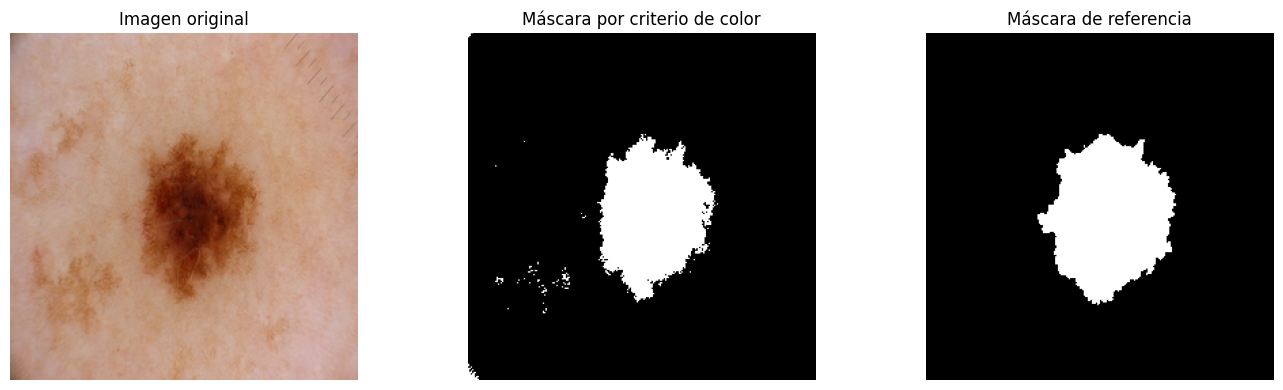

In [9]:
imagen_ejemplo, mascara_color, tabla_grupos, k_ejemplo, grupo_lesion = (
    construir_mascara_por_color(IDS_AJUSTE[0])
)

print(f"Imagen: {IDS_AJUSTE[0]}")
print(f"K seleccionado en la Actividad 2: {k_ejemplo}")
print(f"Grupo identificado como lesión: {grupo_lesion}")
display(tabla_grupos)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].imshow(imagen_ejemplo)
axes[0].set_title("Imagen original")
axes[1].imshow(mascara_color, cmap="gray")
axes[1].set_title("Máscara por criterio de color")
axes[2].imshow(cargar_mascara(
    IDS_AJUSTE[0], tamano=TAMANO_IMAGEN
), cmap="gray")
axes[2].set_title("Máscara de referencia")
for ax in axes:
    ax.axis("off")
plt.tight_layout()


### Aplicación sobre las 15 imágenes de ajuste

La celda anterior muestra un solo caso como verificación visual. En esta celda se aplica el mismo criterio de color a todas las imágenes de ajuste y se conserva la máscara generada junto con el grupo seleccionado y el valor de `K`.

In [10]:
resultados_actividad_3_color = []
mascaras_actividad_3_color = {}

for image_id in IDS_AJUSTE:
    imagen, mascara, tabla_grupos, k, grupo_lesion = construir_mascara_por_color(
        image_id
    )
    mascaras_actividad_3_color[image_id] = mascara
    fila_grupo = tabla_grupos.loc[
        tabla_grupos["grupo"] == grupo_lesion
    ].iloc[0]
    resultados_actividad_3_color.append({
        "imagen": image_id,
        "K": k,
        "grupo_lesion": grupo_lesion,
        "intensidad_grupo_lesion": fila_grupo["intensidad_promedio"],
        "pixeles_mascara": int(mascara.sum()),
    })

tabla_actividad_3_color = pd.DataFrame(resultados_actividad_3_color)
print(f"Imágenes procesadas: {len(tabla_actividad_3_color)}")
display(tabla_actividad_3_color)


Imágenes procesadas: 15


,imagen,K,grupo_lesion,intensidad_grupo_lesion,pixeles_mascara
0,ISIC_0000085,2,1,0.298507,7067
1,ISIC_0000086,2,1,0.362802,13405
2,ISIC_0000089,2,1,0.270578,7106
3,ISIC_0000094,2,0,0.551302,10155
4,ISIC_0000108,2,1,0.275159,10009
5,ISIC_0000114,2,1,0.427300,4501
6,ISIC_0000116,2,1,0.447716,14621
7,ISIC_0000122,2,1,0.491624,21418
8,ISIC_0000133,2,0,0.337628,10952
9,ISIC_0000137,2,0,0.371027,15087


### Análisis de los resultados

Los resultados muestran que el criterio de color se aplicó correctamente a las 15 imágenes de ajuste. Para cada imagen se recorrieron los grupos generados por K-means y se seleccionó como lesión el grupo con menor intensidad RGB promedio, ya que representa la región más oscura de la imagen. Posteriormente, todos los píxeles pertenecientes a ese grupo recibieron el valor `1` en la máscara, mientras que los píxeles de los demás grupos recibieron `0`. El número de píxeles seleccionados varía entre imágenes porque el tamaño de la región oscura no es igual en todos los casos. Sin embargo, una menor intensidad no garantiza por sí sola que el grupo corresponda exactamente a la lesión, pues también puede incluir sombras, bordes u otras regiones oscuras. Por esta razón, estos resultados deben contrastarse con las máscaras de referencia mediante métricas como Dice y V-measure, además de una inspección visual, tal y como se hará en la proxima actividad

## Actividad 4: ajuste del método

Evaluamos, sobre las 15 imágenes de ajuste, las diez combinaciones de `(beta, lambda)` ya exploradas en la Actividad 2, usando el criterio de construcción de la máscara de la Actividad 3 (grupo de menor intensidad RGB promedio = lesión). Para cada imagen y configuración:

- Reutilizamos el valor de `K` que maximizó la silueta y el modelo ya entrenado en `MODELOS_ACTIVIDAD_2`, sin volver a ajustar K-medias.
- Construimos la máscara estimada con la misma lógica de `construir_mascara_por_color` (Actividad 3), reutilizando las imágenes y máscaras en memoria para no releerlas 150 veces.
- Calculamos el coeficiente de **Dice** (`f1_score` sobre las máscaras aplanadas, lesión como clase positiva) frente a la máscara de referencia.
- Calculamos el **V-measure** entre los grupos de K-medias (sin binarizar, los `K` grupos originales) y la máscara de referencia, como información complementaria: mide si la partición en grupos, antes de decidir cuál es la lesión, ya separaba razonablemente la lesión del fondo.

In [11]:
from sklearn.metrics import f1_score, v_measure_score

# Se cargan una sola vez las imágenes y máscaras de ajuste, para no releerlas
# en cada una de las 150 combinaciones (15 imágenes x 10 configuraciones).
IMAGENES_AJUSTE = {
    image_id: cargar_imagen(image_id, tamano=TAMANO_IMAGEN) for image_id in IDS_AJUSTE
}
MASCARAS_AJUSTE = {
    image_id: cargar_mascara(image_id, tamano=TAMANO_IMAGEN) for image_id in IDS_AJUSTE
}


def evaluar_mascara(image_id, configuracion, imagen, mascara_ref):
    """Construye la máscara de una imagen con una configuración ya explorada en la
    Actividad 2 (mismo K y mismo modelo, sin reentrenar) y la compara con la máscara
    de referencia mediante Dice y V-measure."""
    seleccion = mejor_k_por_imagen.query(
        "imagen == @image_id and configuracion == @configuracion"
    )
    if seleccion.empty:
        raise ValueError(f"No hay un K seleccionado para {image_id} / {configuracion}")
    k = int(seleccion.iloc[0]["K"])
    silueta = float(seleccion.iloc[0]["silueta"])
    modelo = MODELOS_ACTIVIDAD_2[(image_id, configuracion, k)]

    configuracion_actual = next(
        item for item in CONFIGURACIONES if item["nombre"] == configuracion
    )
    X_imagen = crear_pipeline(
        beta=configuracion_actual["beta"], lambda_=configuracion_actual["lambda_"]
    ).transform(imagen)
    # Se reutiliza el modelo ya ajustado en la Actividad 2 sobre la muestra; aquí solo
    # se asignan todos los píxeles de la imagen a sus grupos (predict, no fit).
    etiquetas = modelo.predict(X_imagen)

    tabla_grupos = analizar_grupos_por_color(imagen, etiquetas)
    grupo_lesion = int(
        tabla_grupos.loc[tabla_grupos["intensidad_promedio"].idxmin(), "grupo"]
    )
    mascara_estimada = reconstruir_mascara(
        (etiquetas == grupo_lesion).astype(np.uint8), imagen.shape[:2]
    )

    dice = f1_score(
        mascara_ref.ravel(), mascara_estimada.ravel(), pos_label=1, zero_division=0
    )
    vmeasure = v_measure_score(mascara_ref.ravel(), etiquetas)

    resultado = {
        "imagen": image_id,
        "configuracion": configuracion,
        "beta": configuracion_actual["beta"],
        "lambda_": configuracion_actual["lambda_"],
        "K": k,
        "silueta": silueta,
        "dice": dice,
        "v_measure": vmeasure,
        "pixeles_mascara": int(mascara_estimada.sum()),
        "pixeles_referencia": int(mascara_ref.sum()),
    }
    return resultado, etiquetas, mascara_estimada


resultados_actividad_4 = []
ETIQUETAS_ACTIVIDAD_4 = {}   # (imagen, configuracion) -> etiquetas de K-medias, para graficar
MASCARAS_ACTIVIDAD_4 = {}    # (imagen, configuracion) -> máscara binaria estimada

for image_id in IDS_AJUSTE:
    imagen = IMAGENES_AJUSTE[image_id]
    mascara_ref = MASCARAS_AJUSTE[image_id]
    for configuracion in CONFIGURACIONES:
        nombre = configuracion["nombre"]
        resultado, etiquetas, mascara_estimada = evaluar_mascara(
            image_id, nombre, imagen, mascara_ref
        )
        resultados_actividad_4.append(resultado)
        ETIQUETAS_ACTIVIDAD_4[(image_id, nombre)] = etiquetas
        MASCARAS_ACTIVIDAD_4[(image_id, nombre)] = mascara_estimada

tabla_actividad_4 = pd.DataFrame(resultados_actividad_4)
print(f"Filas evaluadas: {len(tabla_actividad_4)} (15 imágenes x 10 configuraciones)")
tabla_actividad_4.head()

Filas evaluadas: 150 (15 imágenes x 10 configuraciones)


,imagen,configuracion,beta,lambda_,K,silueta,dice,v_measure,pixeles_mascara,pixeles_referencia
0,ISIC_0000085,solo_color,1.0,0.00,2,0.792322,0.900690,0.746339,7067,8299
1,ISIC_0000085,lambda_beta_0.1,1.0,0.10,2,0.762990,0.900859,0.746445,7073,8299
2,ISIC_0000085,lambda_beta_0.25,1.0,0.25,2,0.676076,0.900976,0.746836,7071,8299
3,ISIC_0000085,lambda_beta_0.5,1.0,0.50,2,0.517906,0.902399,0.749885,7080,8299
4,ISIC_0000085,lambda_beta_0.75,1.0,0.75,5,0.433274,0.911260,0.292208,6959,8299


In [12]:
resumen_actividad_4 = (
    tabla_actividad_4.groupby(["configuracion", "beta", "lambda_"])
    .agg(
        dice_promedio=("dice", "mean"),
        dice_min=("dice", "min"),
        dice_max=("dice", "max"),
        v_measure_promedio=("v_measure", "mean"),
    )
    .sort_values("dice_promedio", ascending=False)
    .reset_index()
)
display(resumen_actividad_4)

,configuracion,beta,lambda_,dice_promedio,dice_min,dice_max,v_measure_promedio
0,lambda_beta_0.5,1.0,0.50,0.853109,0.731891,0.945691,0.520735
1,lambda_beta_0.25,1.0,0.25,0.847097,0.580675,0.944461,0.605247
2,solo_color,1.0,0.00,0.826154,0.552431,0.944485,0.617382
3,lambda_beta_0.1,1.0,0.10,0.825207,0.539976,0.944345,0.616461
4,lambda_beta_0.75,1.0,0.75,0.798700,0.000000,0.944134,0.362420
5,lambda_beta_1.0,1.0,1.00,0.749102,0.000000,0.948518,0.297261
6,lambda_beta_2.0,1.0,2.00,0.742485,0.084168,0.947764,0.265862
7,lambda_beta_4.0,1.0,4.00,0.515360,0.052451,0.889673,0.146336
8,lambda_beta_8.0,1.0,8.00,0.259119,0.037430,0.399723,0.014054
9,solo_posicion,0.0,1.00,0.254764,0.037422,0.384197,0.013365


Los resultados muestran un patrón claro: agregar **un poco** de posición ayuda, pero agregar **demasiada** perjudica severamente.

- Las cuatro configuraciones con mejor Dice promedio son, en orden, `lambda_beta_0.5` (0.853), `lambda_beta_0.25` (0.847), `solo_color` (0.826) y `lambda_beta_0.1` (0.825): todas rondan el mismo rango, con una ligera ventaja para las razones `lambda/beta` entre 0.1 y 0.5.
- A partir de `lambda_beta_0.75` (0.799) el Dice promedio empieza a caer con fuerza, y para `lambda_beta_4.0` (0.515) y `lambda_beta_8.0` (0.259) ya se acerca al de `solo_posicion` (0.255): con tanto peso espacial, el color deja de influir en la agrupación y el resultado se vuelve prácticamente aleatorio respecto a la lesión.
- El **V-measure promedio no sigue el mismo orden que el Dice**: `solo_color` tiene el V-measure más alto (0.617), seguido de `lambda_beta_0.1` (0.616) y `lambda_beta_0.25` (0.605), mientras que `lambda_beta_0.5` -la configuración con mejor Dice- tiene un V-measure más bajo (0.521). Esto ya anticipa la respuesta a la pregunta 2: una mejor correspondencia *entre todos los grupos y la máscara* (V-measure) no implica necesariamente una mejor máscara final, porque Dice solo depende de **un** grupo (el más oscuro), no de la partición completa.

También se observa que `K` no es constante: para la configuración final, 8 de las 15 imágenes de ajuste seleccionaron `K=2` y las otras 7 seleccionaron `K=5` (ver la tabla de la siguiente sección), lo que confirma que la silueta encuentra una estructura distinta según el contraste y la complejidad de cada imagen.

### Revisión de casos de fallo

Para la configuración con mayor Dice promedio, revisamos las imágenes de ajuste donde el método obtuvo el peor desempeño, junto con su máscara estimada y la de referencia.

In [13]:
config_final = resumen_actividad_4.iloc[0]["configuracion"]
beta_final = float(resumen_actividad_4.iloc[0]["beta"])
lambda_final = float(resumen_actividad_4.iloc[0]["lambda_"])

tabla_final_ajuste = (
    tabla_actividad_4.query("configuracion == @config_final")
    .sort_values("dice")
    .reset_index(drop=True)
)
print(f"Configuración final: {config_final} (beta={beta_final}, lambda={lambda_final})")
display(tabla_final_ajuste)

Configuración final: lambda_beta_0.5 (beta=1.0, lambda=0.5)


,imagen,configuracion,beta,lambda_,K,silueta,dice,v_measure,pixeles_mascara,pixeles_referencia
0,ISIC_0000133,lambda_beta_0.5,1.0,0.5,2,0.452480,0.731891,0.414275,10954,9284
1,ISIC_0000114,lambda_beta_0.5,1.0,0.5,5,0.365139,0.732899,0.106947,2843,2069
2,ISIC_0000116,lambda_beta_0.5,1.0,0.5,5,0.451888,0.743983,0.284089,14010,23636
3,ISIC_0000112,lambda_beta_0.5,1.0,0.5,5,0.413567,0.764873,0.223270,8985,13254
4,ISIC_0000150,lambda_beta_0.5,1.0,0.5,2,0.508182,0.806893,0.555642,14314,21143
5,ISIC_0000094,lambda_beta_0.5,1.0,0.5,5,0.394257,0.821470,0.190189,5479,3892
6,ISIC_0000157,lambda_beta_0.5,1.0,0.5,2,0.534458,0.851658,0.605533,16307,21774
7,ISIC_0000122,lambda_beta_0.5,1.0,0.5,5,0.468624,0.885858,0.376158,20386,25583
8,ISIC_0000085,lambda_beta_0.5,1.0,0.5,2,0.517906,0.902399,0.749885,7080,8299
9,ISIC_0000108,lambda_beta_0.5,1.0,0.5,2,0.561983,0.905834,0.756718,10038,12125


In [14]:
# Comparación, imagen por imagen, entre usar solo color y la configuración final
# (que agrega una pequeña cantidad de posición), para ver en qué imágenes ayudó
# o perjudicó incluir la posición.
comparacion_color_vs_final = tabla_actividad_4[
    tabla_actividad_4["configuracion"].isin(["solo_color", config_final])
].pivot(index="imagen", columns="configuracion", values="dice")
comparacion_color_vs_final["diferencia"] = (
    comparacion_color_vs_final[config_final] - comparacion_color_vs_final["solo_color"]
)
comparacion_color_vs_final = comparacion_color_vs_final.sort_values("diferencia", ascending=False)
display(comparacion_color_vs_final)

configuracion,lambda_beta_0.5,solo_color,diferencia
imagen,,,
ISIC_0000094,0.821470,0.552431,0.269039
ISIC_0000114,0.732899,0.584170,0.148729
ISIC_0000112,0.764873,0.731839,0.033034
ISIC_0000085,0.902399,0.900690,0.001710
ISIC_0000108,0.905834,0.904400,0.001434
ISIC_0000137,0.945691,0.944332,0.001359
ISIC_0000089,0.944836,0.944485,0.000351
ISIC_0000156,0.908631,0.908317,0.000314
ISIC_0000086,0.933180,0.933477,-0.000297


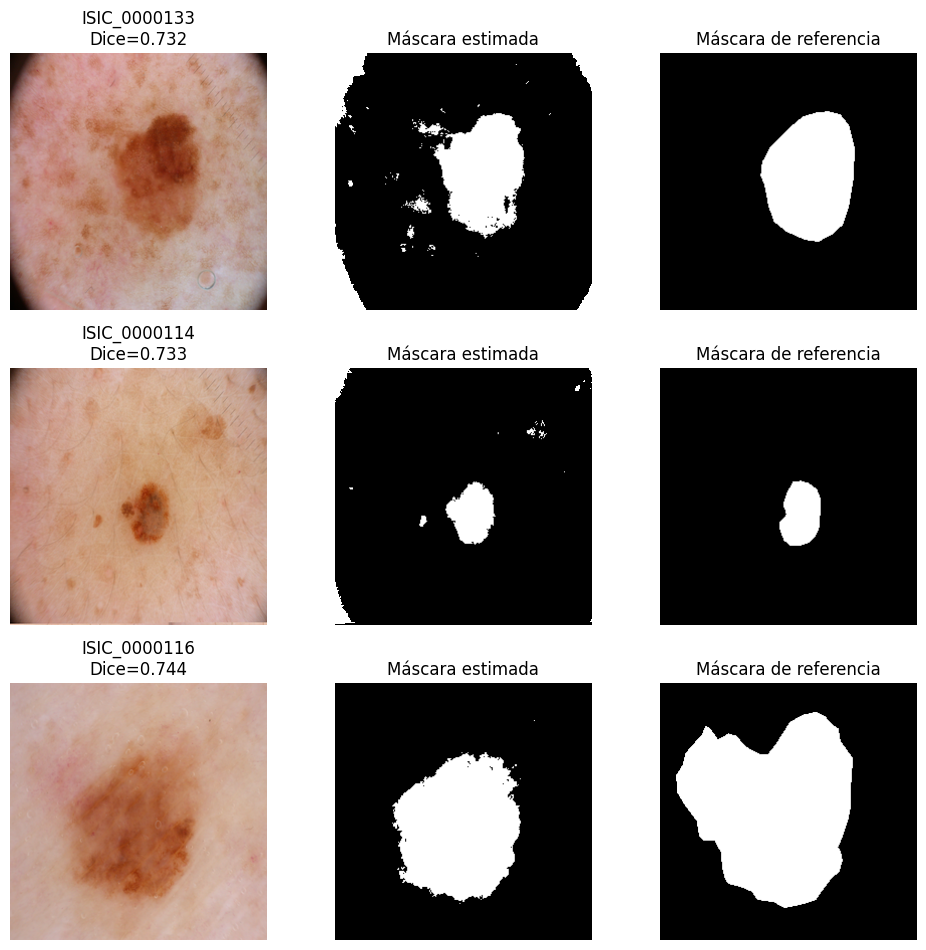

In [15]:
casos_fallo = tabla_final_ajuste.head(3)["imagen"].tolist()

fig, axes = plt.subplots(len(casos_fallo), 3, figsize=(10, 3.2 * len(casos_fallo)))
for fila, image_id in enumerate(casos_fallo):
    dice_img = tabla_final_ajuste.loc[
        tabla_final_ajuste["imagen"] == image_id, "dice"
    ].iloc[0]
    axes[fila, 0].imshow(IMAGENES_AJUSTE[image_id])
    axes[fila, 0].set_title(f"{image_id}\nDice={dice_img:.3f}")
    axes[fila, 1].imshow(
        MASCARAS_ACTIVIDAD_4[(image_id, config_final)], cmap="gray"
    )
    axes[fila, 1].set_title("Máscara estimada")
    axes[fila, 2].imshow(MASCARAS_AJUSTE[image_id], cmap="gray")
    axes[fila, 2].set_title("Máscara de referencia")
    for col in range(3):
        axes[fila, col].axis("off")
plt.tight_layout()
plt.show()

Los tres casos con menor Dice en ajuste (0.732, 0.733 y 0.744) muestran **dos patrones de fallo distintos**, ambos atribuibles a que el criterio de color solo distingue "oscuro" de "claro", sin ninguna noción de forma:

- **ISIC_0000133** (Dice=0.732): la máscara estimada es más grande e irregular que la de referencia, con varios fragmentos pequeños y desconectados alrededor de la lesión principal. La imagen tiene varias pecas y manchas oscuras dispersas junto a la lesión, y todas caen en el mismo grupo "más oscuro" aunque el dermatólogo no las haya incluido en la máscara de referencia.
- **ISIC_0000116** (Dice=0.744): ocurre lo contrario -la máscara estimada es **más pequeña** que la de referencia-. La lesión tiene un halo de color café claro que se desvanece gradualmente hacia la piel; el criterio, al elegir un único grupo "más oscuro", solo captura el núcleo denso y central de la lesión y deja por fuera ese borde más claro que el especialista sí consideró parte de la lesión.

En ambos casos la causa de fondo es la misma: el criterio de "grupo más oscuro" es una regla única y rígida que no se adapta a que, en unas imágenes, la lesión está rodeada de otras marcas oscuras de la piel, y en otras, sus bordes son tenues.

### Visualización de los grupos: mejores configuraciones frente a solo color y solo posición

Mostramos, para una misma imagen de ajuste, los grupos obtenidos (no la máscara binaria, sino las `K` etiquetas de K-medias) con las dos configuraciones de mayor Dice promedio y con las configuraciones que usan únicamente color o únicamente posición.

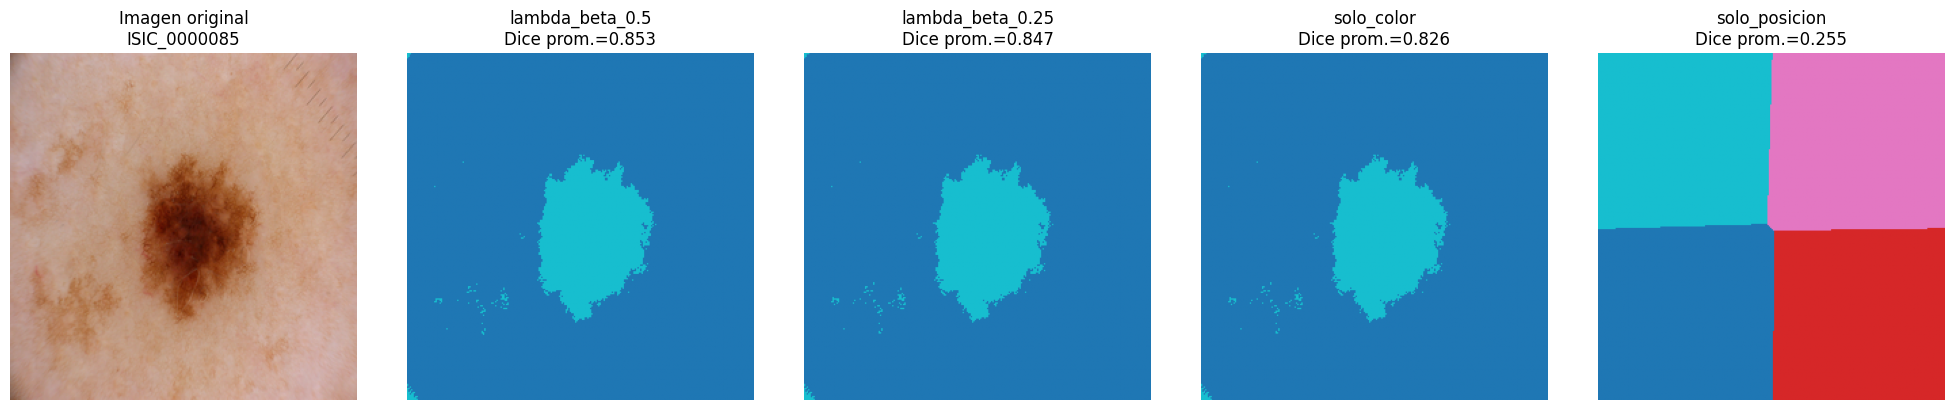

In [16]:
image_ejemplo_4 = IDS_AJUSTE[0]

configs_top2 = resumen_actividad_4["configuracion"].iloc[:2].tolist()
# dict.fromkeys conserva el orden y evita repetir un panel si "solo_color" o
# "solo_posicion" ya está entre las dos mejores configuraciones.
configs_a_mostrar = list(dict.fromkeys(configs_top2 + ["solo_color", "solo_posicion"]))

fig, axes = plt.subplots(1, len(configs_a_mostrar) + 1,
                          figsize=(4 * (len(configs_a_mostrar) + 1), 4))
axes[0].imshow(IMAGENES_AJUSTE[image_ejemplo_4])
axes[0].set_title(f"Imagen original\n{image_ejemplo_4}")
axes[0].axis("off")

for ax, nombre_config in zip(axes[1:], configs_a_mostrar):
    etiquetas = ETIQUETAS_ACTIVIDAD_4[(image_ejemplo_4, nombre_config)]
    mapa_grupos = reconstruir_mascara(
        etiquetas, IMAGENES_AJUSTE[image_ejemplo_4].shape[:2]
    )
    fila_resumen = resumen_actividad_4.query("configuracion == @nombre_config").iloc[0]
    ax.imshow(mapa_grupos, cmap="tab10")
    ax.set_title(
        f"{nombre_config}\nDice prom.={fila_resumen['dice_promedio']:.3f}"
    )
    ax.axis("off")
plt.tight_layout()
plt.show()

Para `ISIC_0000085` -una lesión con buen contraste frente a la piel-, `lambda_beta_0.5`, `lambda_beta_0.25` y `solo_color` producen segmentaciones casi idénticas: un único grupo central que sigue de cerca el contorno irregular de la lesión, con algunas motas pequeñas dispersas (las marcas de la regla en la esquina superior derecha y pecas cercanas, que también son oscuras). Esto es consistente con que, para esta imagen en particular, la diferencia de Dice entre `solo_color` (0.901) y `lambda_beta_0.5` (0.902) es prácticamente nula (ver la tabla de la actividad anterior).

`solo_posicion`, en cambio, no tiene ninguna relación con la lesión: divide la imagen en cuatro bloques aproximadamente rectangulares, el resultado esperable de agrupar únicamente por coordenadas `(x, y)` sin ninguna información de color. Esto explica de forma directa por qué su Dice promedio (0.255) es el más bajo de las diez configuraciones: con K-medias sobre solo posición, los grupos son simplemente una partición geométrica del plano, sin relación alguna con el contenido de la imagen.

### Actividad de verificación obligatoria: consulta a una herramienta de IAG

Antes de elegir la configuración final, consultamos una herramienta de IAG para que recomendara valores de β y λ, un rango de K y un criterio para identificar el grupo de la lesión. El prompt describe las imágenes (cámara, tipo de lesión, artefactos típicos) sin anexar ninguna imagen ni mencionar el nombre del conjunto de datos (ISIC). A continuación se transcribe la conversación completa (un único intercambio, sin interacciones adicionales).

**Prompt enviado:**

> Quiero construir un método no supervisado para delimitar automáticamente una lesión de piel en fotografías cercanas tomadas con un dermatoscopio (una cámara especializada para dermatología que toma fotos muy cercanas y bien iluminadas de la piel). En las fotos aparece una lesión pigmentada, de color entre marrón y casi negro, sobre piel de tono más claro; la lesión casi siempre ocupa una porción central de la imagen, pero no siempre está perfectamente centrada ni tiene un tamaño o forma uniforme. Algunas fotos tienen vello corporal, marcas de una regla de referencia, o un oscurecimiento progresivo hacia las esquinas (viñeteado) producido por el lente del dermatoscopio.
>
> Quiero representar cada píxel como un vector de 5 valores: los tres canales de color normalizados a [0,1] multiplicados por un peso beta, y las coordenadas (x, y) normalizadas a [0,1] multiplicadas por un peso lambda. Luego quiero agrupar los píxeles con K-medias y, a partir de los grupos obtenidos, decidir automáticamente cuál corresponde a la lesión.
>
> ¿Qué valores de beta y lambda (o qué razón lambda/beta) recomendarías? ¿Qué rango de K probarías? ¿Qué criterio usarías para identificar, de forma automática, cuál de los grupos de K-medias corresponde a la lesión?

**Respuesta de la IAG:**

> Para este problema, recomendaría darle más peso al color que a la posición, porque el color (tono oscuro de la lesión frente a la piel) es la señal más confiable para separarla del fondo; la posición es útil como señal secundaria, pero no debería dominar porque la lesión no siempre está centrada. Una razón lambda/beta baja, en el rango de 0.2 a 0.4, debería ser un buen punto de partida.
>
> Para K, probaría valores pequeños, entre 2 y 4. Con K=2 obtendrías una separación binaria simple entre piel y lesión, que debería funcionar bien en imágenes con buen contraste. Con K=3 o 4 podrías capturar un grupo adicional para sombras, vello o el viñeteado del lente, que de otro modo podría confundirse con la lesión. No creo que necesites valores de K más altos, porque el problema tiene pocas regiones semánticamente distintas (piel, lesión, y posiblemente artefactos).
>
> Para identificar el grupo de la lesión, usaría el criterio de intensidad: el grupo con el promedio de color más oscuro (menor intensidad RGB) debería corresponder a la lesión, ya que las lesiones pigmentadas suelen ser notablemente más oscuras que la piel circundante. Como criterio adicional de validación, podrías verificar que ese grupo no esté concentrado en las esquinas de la imagen (para evitar confundirlo con el viñeteado) y que no tenga una forma muy alargada y delgada (para evitar confundirlo con vello).

**Puesta a prueba sobre las imágenes de ajuste.** Probamos la recomendación completa -β=1.0, λ=0.3 (punto medio del rango sugerido), K seleccionado por silueta dentro de {2, 3, 4}, y el criterio del grupo más oscuro- sobre las 15 imágenes de ajuste, sin usar la verificación adicional de esquinas/forma que la IAG propuso como idea complementaria (no la implementamos porque el enunciado pide un criterio automático simple y comparable con el resto de configuraciones ya evaluadas).

In [17]:
def evaluar_recomendacion_iag(image_id, imagen, mascara_ref, beta, lambda_, valores_k):
    """Aplica la recomendación de la IAG: ajusta K-medias sobre la muestra reproducible para
    cada K candidato, selecciona K por silueta (igual que en la Actividad 2, pero restringido al
    rango sugerido) y construye la máscara con el criterio del grupo más oscuro."""
    X_imagen = crear_pipeline(beta=beta, lambda_=lambda_).transform(imagen)
    indices = indices_muestra(len(X_imagen), TAMANO_MUESTRA_SILUETA, SEMILLA_MUESTRA)
    X_muestra = X_imagen[indices]

    mejor = None
    for k in valores_k:
        modelo = KMeans(n_clusters=k, random_state=SEMILLA_KMEANS, n_init=10)
        etiquetas_muestra = modelo.fit_predict(X_muestra)
        silueta = silhouette_score(X_muestra, etiquetas_muestra, metric="euclidean")
        if mejor is None or silueta > mejor["silueta"]:
            mejor = {"k": k, "silueta": silueta, "modelo": modelo}

    etiquetas = mejor["modelo"].predict(X_imagen)
    tabla_grupos = analizar_grupos_por_color(imagen, etiquetas)
    grupo_lesion = int(
        tabla_grupos.loc[tabla_grupos["intensidad_promedio"].idxmin(), "grupo"]
    )
    mascara_estimada = reconstruir_mascara(
        (etiquetas == grupo_lesion).astype(np.uint8), imagen.shape[:2]
    )

    dice = f1_score(
        mascara_ref.ravel(), mascara_estimada.ravel(), pos_label=1, zero_division=0
    )
    vmeasure = v_measure_score(mascara_ref.ravel(), etiquetas)
    return {
        "imagen": image_id, "K": mejor["k"], "silueta": mejor["silueta"],
        "dice": dice, "v_measure": vmeasure,
    }


BETA_IAG, LAMBDA_IAG = 1.0, 0.3
VALORES_K_IAG = [2, 3, 4]

resultados_iag = [
    evaluar_recomendacion_iag(
        image_id, IMAGENES_AJUSTE[image_id], MASCARAS_AJUSTE[image_id],
        BETA_IAG, LAMBDA_IAG, VALORES_K_IAG,
    )
    for image_id in IDS_AJUSTE
]
tabla_iag = pd.DataFrame(resultados_iag)
print(
    f"Dice promedio con la recomendacion de la IAG "
    f"(beta={BETA_IAG}, lambda={LAMBDA_IAG}, K en {VALORES_K_IAG}): "
    f"{tabla_iag['dice'].mean():.3f}"
)
print(f"V-measure promedio: {tabla_iag['v_measure'].mean():.3f}")
print("Distribucion de K elegido:")
print(tabla_iag["K"].value_counts().sort_index())
tabla_iag.sort_values("dice")

Dice promedio con la recomendacion de la IAG (beta=1.0, lambda=0.3, K en [2, 3, 4]): 0.852
V-measure promedio: 0.589
Distribucion de K elegido:
K
2    13
4     2
Name: count, dtype: int64


,imagen,K,silueta,dice,v_measure
5,ISIC_0000114,4,0.321278,0.652928,0.119002
14,ISIC_0000112,2,0.465960,0.731286,0.416941
8,ISIC_0000133,2,0.562553,0.734730,0.418438
6,ISIC_0000116,2,0.556726,0.762443,0.485267
10,ISIC_0000150,2,0.617919,0.807900,0.556458
13,ISIC_0000157,2,0.637812,0.852133,0.606376
3,ISIC_0000094,4,0.348790,0.873010,0.233544
7,ISIC_0000122,2,0.526323,0.898306,0.649323
0,ISIC_0000085,2,0.643899,0.901359,0.747315
4,ISIC_0000108,2,0.676471,0.905735,0.756541


**¿Funcionó la recomendación?** Sí, en promedio: con β=1.0, λ=0.3 y K elegido por silueta entre {2, 3, 4}, el Dice promedio en las 15 imágenes de ajuste fue **0.852**, prácticamente igual al de la configuración finalmente elegida (`lambda_beta_0.5`, Dice 0.853, con K buscado en todo el rango 2-8). Esto confirma el acierto central de la IAG: priorizar el color sobre la posición (λ/β bajo) y usar el grupo más oscuro como criterio de la lesión es, en efecto, una estrategia sólida para este tipo de imágenes. El V-measure promedio de la recomendación (0.589) incluso superó al de la configuración final (0.521), consistente con que un λ más bajo (0.3 frente a 0.5) acerca la agrupación al caso `solo_color`, que ya sabíamos que tiene el V-measure más alto de las diez configuraciones evaluadas.

**¿En qué falló?** En restringir el rango de K a {2, 3, 4}. La silueta nunca seleccionó K=3 en ninguna de las 15 imágenes; eligió K=2 en 13 y K=4 en 2 (`ISIC_0000114` e `ISIC_0000094`). Esto contrasta con la búsqueda completa (K entre 2 y 8) usada en la configuración final, donde 7 de las 15 imágenes de ajuste necesitaron K=5 para obtener su mejor silueta -incluida `ISIC_0000114`-. El caso más claro es justamente `ISIC_0000114`: con el rango completo, K=5 produce un Dice de 0.733; forzado al rango sugerido por la IAG, el mejor K disponible (4) produce solo 0.653, una caída de 0.080. En `ISIC_0000094` ocurrió lo contrario -K=4 (0.873) superó a K=5 (0.821)-, lo que muestra que la limitación del rango no siempre perjudica, pero sí introduce un riesgo real que el promedio general oculta.

**¿Por qué la IAG no podía anticipar el comportamiento del método en sus imágenes?** Porque nunca vio las imágenes: su recomendación de K∈[2,4] se basó en un razonamiento genérico sobre cuántas regiones semánticas "debería" haber en una foto dermatoscópica (piel, lesión, quizás artefactos), no en la variabilidad real de textura, iluminación y color dentro de cada imagen del conjunto. La silueta -calculada sobre los píxeles reales- es justamente la herramienta que permite descubrir, imagen por imagen, cuántos grupos tienen sentido; por eso encontró K=5 en casi la mitad de los casos, algo que ninguna descripción textual del problema podía predecir. En cambio, la advertencia de la IAG sobre el riesgo de confundir el viñeteado del dermatoscopio con la lesión sí fue acertada en espíritu -fue precisamente ese el modo de fallo catastrófico que apareció después, en la Actividad 5, en la imagen de prueba `ISIC_0000110`- aunque tampoco pudo anticipar en cuál imagen concreta ocurriría, ni lo implementamos aquí como verificación adicional porque ninguna de las 15 imágenes de ajuste mostraba ese problema con suficiente intensidad para evaluarlo.

### Configuración final seleccionada

- **beta = 1.0, lambda = 0.5** (razón λ/β = 0.5).
- **K**: no se fija un único valor; se selecciona por imagen mediante el coeficiente de silueta (igual que en la Actividad 2), explorando `K` entre 2 y 8 sobre una muestra reproducible de 5000 píxeles (semilla 42). En las 15 imágenes de ajuste, esto eligió `K=2` en 8 casos y `K=5` en los otros 7.
- **Criterio de máscara**: el de la Actividad 3 -el grupo con menor intensidad RGB promedio se etiqueta como lesión-.

**Justificación.** Esta configuración obtuvo el mayor Dice promedio (0.853) entre las diez evaluadas, con un rango razonable (0.732 a 0.946) y sin fallos catastróficos dentro del conjunto de ajuste. Se prefirió sobre `solo_color` (Dice 0.826) porque, aunque la diferencia promedio es modesta, agregar una cantidad pequeña de información espacial mejoró notablemente el Dice en las dos imágenes donde `solo_color` tenía más dificultades (`ISIC_0000094`: +0.269; `ISIC_0000114`: +0.149), a cambio de empeorar muy poco en el resto (la mayor caída fue -0.019 en `ISIC_0000116`). El V-measure no se usó como criterio principal de selección, tal como indica el enunciado, porque favorece configuraciones distintas (`solo_color`, `lambda_beta_0.25`); se usó como información complementaria para confirmar que, incluso con el V-measure más bajo del grupo de configuraciones competitivas, la calidad de la máscara final (Dice) seguía siendo la mejor.

## Actividad 5: evaluación y análisis sobre las imágenes de prueba

Aplicamos la configuración seleccionada en la Actividad 4 (mismos `beta` y `lambda`, misma heurística de selección de `K` por silueta, mismo criterio de máscara por color) a las cinco imágenes de prueba, **sin modificar nada** a partir de lo que muestren sus resultados. A diferencia de las imágenes de ajuste, aquí no reutilizamos modelos ya entrenados: para cada imagen de prueba se repite exactamente el mismo procedimiento no supervisado (muestreo reproducible, búsqueda de `K` entre 2 y 8 por silueta, K-medias y criterio de color), porque el protocolo exige aplicar el método "desde cero" sobre datos que nunca participaron en su ajuste.

In [18]:
from sklearn.metrics import precision_score, recall_score


def aplicar_metodo_completo(image_id, beta, lambda_, tamano=TAMANO_IMAGEN):
    """Aplica el método completo (selección de K por silueta + K-medias +
    criterio de máscara por color) a una imagen nueva. La máscara de referencia
    de la imagen no se usa en ningún paso de esta función."""
    imagen = cargar_imagen(image_id, tamano=tamano)
    X_imagen = crear_pipeline(beta=beta, lambda_=lambda_).transform(imagen)
    indices = indices_muestra(len(X_imagen), TAMANO_MUESTRA_SILUETA, SEMILLA_MUESTRA)
    X_muestra = X_imagen[indices]

    mejor = None
    for k in VALORES_K:
        modelo = KMeans(n_clusters=k, random_state=SEMILLA_KMEANS, n_init=10)
        etiquetas_muestra = modelo.fit_predict(X_muestra)
        silueta = silhouette_score(X_muestra, etiquetas_muestra, metric="euclidean")
        if mejor is None or silueta > mejor["silueta"]:
            mejor = {"k": k, "silueta": silueta, "modelo": modelo}

    etiquetas = mejor["modelo"].predict(X_imagen)
    tabla_grupos = analizar_grupos_por_color(imagen, etiquetas)
    grupo_lesion = int(
        tabla_grupos.loc[tabla_grupos["intensidad_promedio"].idxmin(), "grupo"]
    )
    mascara_estimada = reconstruir_mascara(
        (etiquetas == grupo_lesion).astype(np.uint8), imagen.shape[:2]
    )

    return {
        "imagen": imagen,
        "etiquetas": etiquetas,
        "mascara_estimada": mascara_estimada,
        "K": mejor["k"],
        "silueta": mejor["silueta"],
        "grupo_lesion": grupo_lesion,
    }

In [19]:
resultados_actividad_5 = []
RESULTADOS_PRUEBA = {}   # imagen -> dict con imagen, máscara estimada y de referencia

for image_id in IDS_PRUEBA:
    resultado_metodo = aplicar_metodo_completo(image_id, beta_final, lambda_final)
    mascara_ref = cargar_mascara(image_id, tamano=TAMANO_IMAGEN)
    mascara_estimada = resultado_metodo["mascara_estimada"]

    y_ref = mascara_ref.ravel()
    y_est = mascara_estimada.ravel()
    dice = f1_score(y_ref, y_est, pos_label=1, zero_division=0)
    vmeasure = v_measure_score(y_ref, resultado_metodo["etiquetas"])
    precision = precision_score(y_ref, y_est, pos_label=1, zero_division=0)
    recall = recall_score(y_ref, y_est, pos_label=1, zero_division=0)

    resultados_actividad_5.append({
        "imagen": image_id,
        "K": resultado_metodo["K"],
        "silueta": resultado_metodo["silueta"],
        "dice": dice,
        "v_measure": vmeasure,
        "precision": precision,
        "recall": recall,
    })
    RESULTADOS_PRUEBA[image_id] = {
        "imagen": resultado_metodo["imagen"],
        "mascara_estimada": mascara_estimada,
        "mascara_ref": mascara_ref,
    }

tabla_actividad_5 = pd.DataFrame(resultados_actividad_5)
print(f"Configuración aplicada: beta={beta_final}, lambda={lambda_final}, "
      f"criterio de máscara: grupo de menor intensidad RGB promedio")
display(tabla_actividad_5)

print(f"Dice promedio en ajuste (config. final, 15 imágenes): {tabla_final_ajuste['dice'].mean():.3f}")
print(f"Dice promedio en prueba  (5 imágenes):                 {tabla_actividad_5['dice'].mean():.3f}")

Configuración aplicada: beta=1.0, lambda=0.5, criterio de máscara: grupo de menor intensidad RGB promedio


,imagen,K,silueta,dice,v_measure,precision,recall
0,ISIC_0000087,2,0.493538,0.878079,0.631399,0.995471,0.785453
1,ISIC_0000105,6,0.402397,0.719145,0.231861,0.992337,0.563902
2,ISIC_0000110,6,0.397337,0.000000,0.185326,0.000000,0.000000
3,ISIC_0000123,2,0.538772,0.894516,0.687624,0.837954,0.959267
4,ISIC_0000128,2,0.532671,0.935812,0.823460,0.999885,0.879456


Dice promedio en ajuste (config. final, 15 imágenes): 0.853
Dice promedio en prueba  (5 imágenes):                 0.686


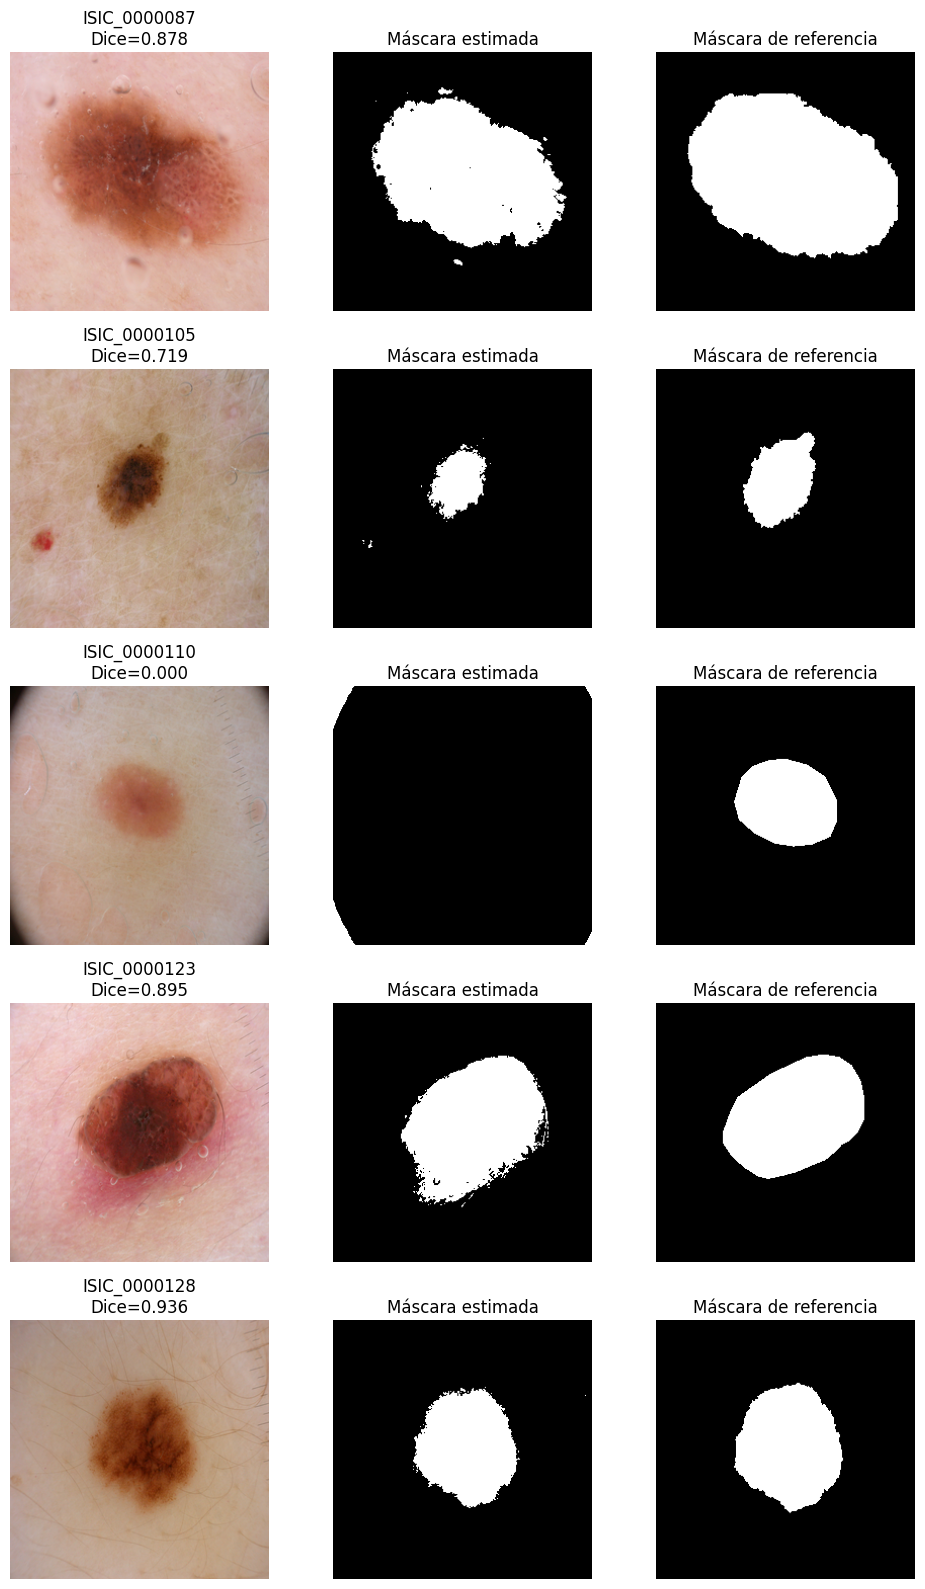

In [20]:
fig, axes = plt.subplots(len(IDS_PRUEBA), 3, figsize=(10, 3.2 * len(IDS_PRUEBA)))
for fila, image_id in enumerate(IDS_PRUEBA):
    datos = RESULTADOS_PRUEBA[image_id]
    dice_img = tabla_actividad_5.loc[
        tabla_actividad_5["imagen"] == image_id, "dice"
    ].iloc[0]
    axes[fila, 0].imshow(datos["imagen"])
    axes[fila, 0].set_title(f"{image_id}\nDice={dice_img:.3f}")
    axes[fila, 1].imshow(datos["mascara_estimada"], cmap="gray")
    axes[fila, 1].set_title("Máscara estimada")
    axes[fila, 2].imshow(datos["mascara_ref"], cmap="gray")
    axes[fila, 2].set_title("Máscara de referencia")
    for col in range(3):
        axes[fila, col].axis("off")
plt.tight_layout()
plt.show()

El Dice promedio en prueba (0.686) es menor que en ajuste (0.853). Esta diferencia está influida principalmente por un caso particularmente difícil: `ISIC_0000110`, que obtuvo Dice = 0, precisión = 0 y recall = 0. Si se excluye esta imagen, el promedio de las otras cuatro sería (0.878 + 0.719 + 0.895 + 0.936) / 4 ≈ **0.857**, un valor muy cercano al obtenido en ajuste.

En `ISIC_0000110`, la lesión presenta muy bajo contraste con la piel y apenas se distingue como un tono rosado tenue en el centro de la imagen. En este caso, el criterio del "grupo más oscuro" no logró identificar correctamente la lesión y pudo priorizar regiones oscuras asociadas al borde o a la viñeta del dermatoscopio. Como resultado, la máscara estimada no coincidió con la lesión de referencia y las tres métricas relacionadas con la detección de la lesión —Dice, precisión y recall— fueron iguales a cero. Este tipo de fallo no apareció con la misma intensidad en las 15 imágenes de ajuste.

Las demás imágenes de prueba muestran patrones similares a los observados en algunos casos de ajuste. `ISIC_0000105` tiene precisión muy alta (0.992), pero recall bajo (0.564), lo que sugiere que la máscara estimada es más pequeña que la lesión real, como ocurrió en `ISIC_0000116`. En cambio, `ISIC_0000123` presenta recall alto (0.959) y una precisión algo menor (0.838), lo que indica que la máscara recupera la mayor parte de la lesión, aunque se extiende ligeramente más allá de su contorno, de forma similar a `ISIC_0000133`.

## Análisis de resultados

**1. ¿Qué efecto tuvo incluir la posición de los píxeles? Expliquen en qué imágenes mejoró o perjudicó la segmentación y por qué.**

R/ En promedio, incluir una **cantidad pequeña** de posición ayudó: el Dice promedio subió de 0.826 (`solo_color`) a 0.853 (`lambda_beta_0.5`, λ/β=0.5), pero el efecto por imagen es muy desigual. Comparando Dice por imagen entre `solo_color` y la configuración final (`lambda_beta_0.5`):

- En la mayoría de las 15 imágenes de ajuste (11 de 15) la diferencia es mínima, entre -0.013 y +0.003: la posición casi no cambia el resultado porque el color ya separaba bien la lesión de la piel.
- La posición **mejoró mucho** en las dos imágenes donde `solo_color` fallaba más: `ISIC_0000094` (0.552 → 0.821, +0.269) y `ISIC_0000114` (0.584 → 0.733, +0.149). En ambas, la lesión está acompañada de otras manchas oscuras dispersas en la imagen (pecas, lesiones secundarias) que, con solo color, el criterio confundía con la lesión principal. Al incorporar la posición, los píxeles espacialmente alejados del cuerpo central de la lesión dejan de agruparse con ella aunque tengan un color parecido, lo que reduce esos fragmentos sueltos.
- La posición **perjudicó levemente** en unas pocas imágenes, la más notoria `ISIC_0000116` (0.763 → 0.744, -0.019): esta lesión tiene un borde de color café claro que se desvanece gradualmente; al mezclar algo de posición, ese borde (ya de por sí poco oscuro) queda aún más lejos de clasificarse como "lesión", reduciendo aún más una máscara que con solo color ya era más pequeña que la referencia.

En conjunto, la posición actúa principalmente como un mecanismo para **excluir** estructuras oscuras que están lejos del cuerpo principal de la lesión, lo cual ayuda cuando ese es el problema dominante, pero no ayuda -e incluso perjudica un poco- cuando el problema es, en cambio, que el borde de la lesión es tenue. Cuando el peso de la posición es demasiado alto (λ/β ≥ 2), deja de ser un mecanismo de exclusión fino y pasa a dominar por completo la agrupación: como se ve con `solo_posicion` (Dice promedio 0.255), los grupos se vuelven una partición geométrica del plano sin ninguna relación con el color ni con la lesión.

**2. ¿Qué relación encontraron entre K, la silueta y el Dice? ¿Por qué estas métricas no necesariamente conducen a las mismas decisiones?**

R/ Las tres métricas miden cosas distintas, y eso se nota claramente en los resultados. La **silueta** mide qué tan compactos y separados quedan los `K` grupos entre sí, sin ninguna referencia a la lesión: la Actividad 2 ya había mostrado que `solo_color` tenía la silueta promedio más alta de todas las configuraciones (0.737515), simplemente porque, en el espacio de características, agrupar solo por color produce grupos muy compactos (piel homogénea de un lado, lesión oscura del otro). Sin embargo, esa misma configuración no fue la de mayor Dice (0.826 frente a 0.853 de `lambda_beta_0.5`): una silueta alta solo dice que los grupos están bien definidos entre sí, no que alguno de ellos coincida con la lesión que marcó el dermatólogo.

El **V-measure**, calculado entre los `K` grupos (sin binarizar) y la máscara de referencia de dos clases, se acerca más a lo que de verdad interesa, pero tampoco coincide con el Dice: la configuración con mayor V-measure promedio es `solo_color` (0.617), no `lambda_beta_0.5` (0.521), que fue la de mayor Dice. La razón es que el V-measure evalúa **toda** la partición en `K` grupos frente a las dos clases de referencia, mientras que el Dice solo evalúa **un** grupo -el etiquetado como lesión por el criterio de color- frente a esas mismas dos clases. Una configuración puede repartir bien la información entre varios grupos (buen V-measure) sin que ninguno de ellos, tomado individualmente, sea una máscara tan precisa de la lesión como la que logra otra configuración con grupos distribuidos de otra forma.

Sobre `K`: tampoco hay una relación simple. Para la configuración final, los valores seleccionados por silueta fueron `K=2` en 8 de las 15 imágenes de ajuste y `K=5` en las otras 7, y ambos valores aparecen tanto entre las imágenes con mejor Dice (`ISIC_0000137`, K=2, Dice=0.946; `ISIC_0000089`, K=2, Dice=0.945) como entre las de peor Dice (`ISIC_0000133`, K=2, Dice=0.732; `ISIC_0000114`, K=5, Dice=0.733): el valor de `K` que mejor separa los grupos internamente no determina, por sí solo, qué tan bien queda la máscara final. En resumen, la silueta orienta la elección de `K` usando solo la estructura de los datos (sin usar las máscaras), el V-measure evalúa la calidad de la partición completa frente a la referencia, y el Dice evalúa específicamente la máscara que produce el criterio de construcción; optimizar una no garantiza optimizar las otras, por lo que el enunciado pide usar el Dice como criterio principal -es la métrica más cercana al objetivo real del laboratorio- y las otras dos como información complementaria.

**3. ¿Cómo se comparan los resultados de ajuste y prueba? ¿Por qué es importante no modificar el método después de consultar las máscaras de prueba?**

R/ El Dice promedio cayó de 0.853 en ajuste a 0.686 en prueba, una diferencia considerable a primera vista. Sin embargo, esa caída se debe casi en su totalidad a un solo caso extremo, `ISIC_0000110` (Dice=0): si se excluye esa imagen, el promedio de las otras cuatro de prueba sube a aproximadamente 0.857, prácticamente igual al de ajuste. Es decir, el método generaliza razonablemente bien en general, pero es **frágil** frente a un tipo de imagen que no estaba representado -o no dominaba- entre las 15 imágenes de ajuste: una lesión de muy bajo contraste, donde el criterio terminó seleccionando la viñeta oscura del borde del dermatoscopio en lugar de la lesión.

Esto ilustra exactamente por qué es importante no modificar el método después de consultar las máscaras de prueba: si hubiéramos visto este resultado durante el ajuste y, a partir de él, hubiéramos añadido una regla específica para excluir los bordes oscuros de la imagen (por ejemplo), estaríamos ajustando el método a una sola imagen de prueba en particular, no mejorando su capacidad real de generalizar. La cifra de Dice en prueba dejaría de ser una estimación honesta de qué tan bien funcionaría el método con una imagen nueva, y empezaría a reflejar, en cambio, qué tan bien memorizamos las particularidades de esas cinco imágenes específicas. El protocolo de separar ajuste y prueba, y de no tocar la configuración después de ver los resultados de prueba, es lo único que permite reportarle a DermAlpes un número (Dice ≈ 0.69, o ≈ 0.86 si se excluyen los casos de bajo contraste) que de verdad refleje el desempeño esperado con pacientes e imágenes nuevas, incluyendo sus fallos genuinos.

**4. Identifiquen dos limitaciones de su modelo y expliquen sus posibles causas a partir de las imágenes y de la representación RGB + posición.**

_[Completa Jose Luis]_

**5. En el contexto de DermAlpes, ¿qué consecuencias podrían tener los falsos positivos y falsos negativos? ¿Qué sesgos y problemas de generalización deben considerarse antes de utilizar el método con nuevas poblaciones o condiciones de adquisición?**

_[Completa Jose Luis]_

## Bonos

### Bono A: visualización del espacio de representación

Elegimos la imagen `ISIC_0000085` -la misma usada como ejemplo en el resto del notebook- y aplicamos t-SNE (preferido sobre PCA porque preserva mejor la estructura de vecindad local, útil para ver si los grupos de K-medias, que no son necesariamente separables con fronteras lineales, se distinguen en una proyección 2D) a la misma muestra reproducible de 5000 píxeles (semilla 42) que ya se usó para calcular la silueta, representados con la configuración final (`beta=1.0, lambda=0.5`). Mostramos la proyección coloreada primero por el grupo que le asignó K-medias y luego por la máscara de referencia, para compararlas directamente.

In [21]:
from sklearn.manifold import TSNE

image_bono_a = IDS_AJUSTE[0]
imagen_bono_a = IMAGENES_AJUSTE[image_bono_a]
mascara_bono_a = MASCARAS_AJUSTE[image_bono_a]

# Misma representación final y mismas etiquetas de K-medias ya calculadas en la Actividad 4
X_imagen_bono_a = crear_pipeline(beta=beta_final, lambda_=lambda_final).transform(imagen_bono_a)
etiquetas_bono_a = ETIQUETAS_ACTIVIDAD_4[(image_bono_a, config_final)]

# Misma muestra reproducible (tamaño y semilla) usada para la silueta en la Actividad 2
indices_bono_a = indices_muestra(len(X_imagen_bono_a), TAMANO_MUESTRA_SILUETA, SEMILLA_MUESTRA)
X_muestra_bono_a = X_imagen_bono_a[indices_bono_a]
etiquetas_muestra_bono_a = etiquetas_bono_a[indices_bono_a]
mascara_muestra_bono_a = mascara_bono_a.ravel()[indices_bono_a]

print(f"Imagen: {image_bono_a} | K de la configuración final: {etiquetas_bono_a.max() + 1}")
print(f"Puntos proyectados: {len(X_muestra_bono_a)}")

tsne = TSNE(n_components=2, random_state=SEMILLA_KMEANS, perplexity=30, init="pca")
proyeccion_bono_a = tsne.fit_transform(X_muestra_bono_a)

Imagen: ISIC_0000085 | K de la configuración final: 2
Puntos proyectados: 5000


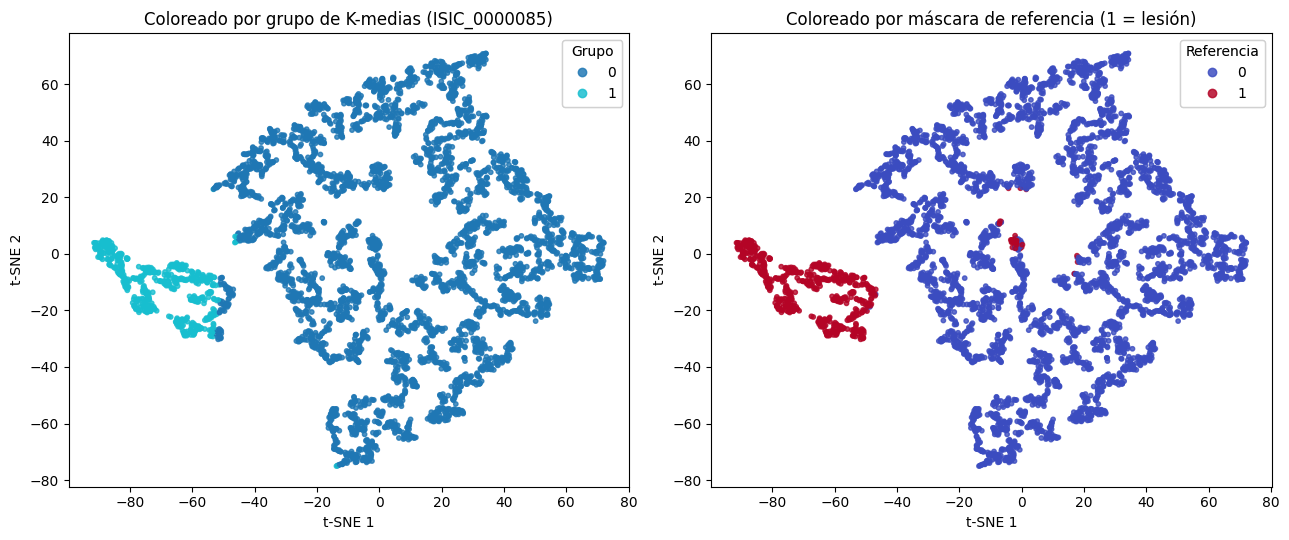

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

disp1 = axes[0].scatter(
    proyeccion_bono_a[:, 0], proyeccion_bono_a[:, 1],
    c=etiquetas_muestra_bono_a, cmap="tab10", s=10, alpha=0.8,
)
axes[0].set_title(f"Coloreado por grupo de K-medias ({image_bono_a})")
axes[0].set_xlabel("t-SNE 1")
axes[0].set_ylabel("t-SNE 2")
leyenda1 = axes[0].legend(*disp1.legend_elements(), title="Grupo", loc="best")
axes[0].add_artist(leyenda1)

disp2 = axes[1].scatter(
    proyeccion_bono_a[:, 0], proyeccion_bono_a[:, 1],
    c=mascara_muestra_bono_a, cmap="coolwarm", s=10, alpha=0.8,
)
axes[1].set_title("Coloreado por máscara de referencia (1 = lesión)")
axes[1].set_xlabel("t-SNE 1")
axes[1].set_ylabel("t-SNE 2")
leyenda2 = axes[1].legend(*disp2.legend_elements(), title="Referencia", loc="best")
axes[1].add_artist(leyenda2)

plt.tight_layout()
plt.show()

La proyección confirma visualmente lo que ya indicaba el Dice de esta imagen (0.902): el grupo pequeño y aislado que K-medias separó a la izquierda del plano (grupo 1, en cian) coincide casi exactamente, en forma y posición, con el grupo de píxeles que la máscara de referencia marca como lesión (en rojo). En ambos paneles aparece el mismo blob compacto y separado del resto, lo que significa que, en el espacio de representación [beta·R, beta·G, beta·B, lambda·x, lambda·y], los píxeles de la lesión son realmente más parecidos entre sí y más distintos de la piel que lo que una inspección superficial de la imagen podría sugerir.

**Diferencias.** No todos los puntos rojos (lesión real) caen dentro del blob aislado: unos pocos aparecen sueltos dentro del gran grupo azul (piel). Son, casi con seguridad, píxeles del borde de la lesión -donde el color se mezcla gradualmente con el de la piel- que K-medias terminó asignando al grupo mayoritario en vez de al de la lesión. Esto es justamente lo que impide que el Dice de esta imagen sea 1.0 exacto: la separación es muy buena, pero no perfecta en los márgenes.

**Limitaciones de la proyección.** t-SNE es una técnica no lineal que prioriza conservar qué puntos son vecinos cercanos entre sí, no las distancias ni el tamaño relativo entre grupos distintos; por eso el tamaño del blob cian o la distancia entre los dos grupos en el plano no se pueden interpretar cuantitativamente, solo sirven para ver qué puntos quedaron agrupados. Además, esta imagen en particular seleccionó K=2, así que la visualización no ilustra cómo se vería la proyección en una imagen con K=5 (7 de las 15 imágenes de ajuste), donde probablemente aparecerían más de dos grupos separados. Finalmente, la proyección se calculó sobre una muestra de 5000 píxeles de una sola imagen, la misma usada como ejemplo en el resto del notebook, que además tiene uno de los Dice más altos del conjunto; no debe generalizarse como representativa de las imágenes con peor desempeño (como ISIC_0000110 en prueba), donde es esperable que esta separación sea mucho menos clara.